## Task 1

In [1]:
import numpy as np

def eigen(A):
    eigenvalues, eigenvectors = np.linalg.eig(A)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    for i in range(len(eigenvalues)):
        lam = eigenvalues[i]
        v = eigenvectors[:,i]
        formula = np.allclose(A @ v, lam * v)
        print(f"Lam = {lam}, v = {v}, check: {formula}")
        
    return eigenvalues, eigenvectors

In [2]:
vals, vecs = eigen(np.array([[4, 0], [0, 1]]))

Lam = 4.0, v = [1. 0.], check: True
Lam = 1.0, v = [0. 1.], check: True


In [3]:
vals, vecs = eigen(np.array([[2, 1], [1, 2]]))

Lam = 3.0, v = [0.70710678 0.70710678], check: True
Lam = 1.0, v = [-0.70710678  0.70710678], check: True


## Task 3

In [4]:
def decrypt_message(encrypted_vector, key_matrix):
    eigenvalues, eigenvectors = np.linalg.eig(key_matrix)
    inv_key = eigenvectors @ np.diag(1 / eigenvalues) @ np.linalg.inv(eigenvectors)
    sms_num = inv_key @ encrypted_vector
    codes = np.round(np.real(sms_num)).astype(int)
    result = ''.join([chr(num) for num in codes])
    return result

In [5]:
def encrypt_message(message, key_matrix):
    message_vector = np.array([ord(char) for char in message])
    eigenvalues, eigenvectors = np.linalg.eig(key_matrix)
    diagonalized_key_matrix = np.dot(np.dot(eigenvectors, np.diag(eigenvalues)), np.linalg.inv(eigenvectors))
    encrypted_vector = np.dot(diagonalized_key_matrix, message_vector)
    return encrypted_vector

message = "Hello, World!"
key_matrix = np.random.randint(0, 256, (len(message), len(message)))

encrypted = encrypt_message(message, key_matrix)
decrypted = decrypt_message(encrypted, key_matrix)

print("Original Message:", message)
print("Encrypted Message:", encrypted)
print("Decrypted Message:", decrypted)

Original Message: Hello, World!
Encrypted Message: [115421.+1.54218279e-11j 163739.+1.91332466e-11j 145339.+2.01913135e-11j
 126655.+1.49848748e-11j 124488.+1.69034985e-11j 171714.+3.05030480e-11j
 158145.+2.25418596e-11j 155611.+1.70976514e-11j 141634.+8.71401029e-12j
 129597.+1.00749566e-11j 153132.+1.67818814e-11j 127784.+7.08030246e-12j
 163874.+3.54063489e-11j]
Decrypted Message: Hello, World!


## Task 2

(691, 1095, 3)


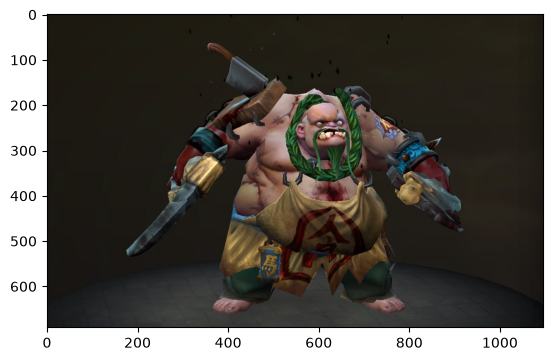

(691, 1095)
1.0


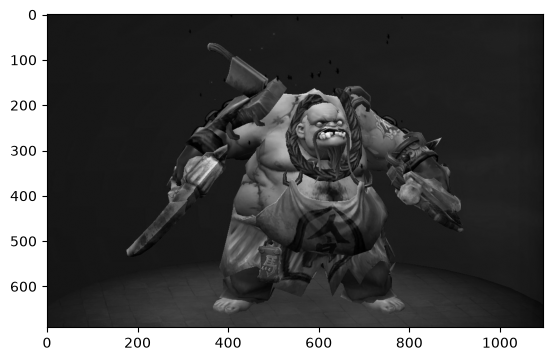

In [6]:
from matplotlib.image import imread
import matplotlib.pyplot as plt
image_raw = imread("photo.jpg")
print(image_raw.shape)
plt.imshow(image_raw)
plt.show()
image_sum = image_raw.sum(axis=2)
print(image_sum.shape)
image_bw = image_sum/image_sum.max()
print(image_bw.max())
plt.imshow(image_bw, cmap='gray')
plt.show()

In [7]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(image_bw)

cum_var = np.cumsum(pca.explained_variance_ratio_) * 100

print(cum_var[:10])

k = np.argmax(cum_var >= 95) + 1
print("Number of components explaining 95% variance:", k)

[31.76141258 42.70922222 50.65383456 58.01074376 63.03690963 67.41092753
 70.53622211 72.94498931 75.05877905 76.84324383]
Number of components explaining 95% variance: 56


5% дисперсії охоплюється 56 компонентами із 691. Усі об'єкти
можна розпізнати, але зображення розмите: дрібні деталі та різкість
втрачені, бо вони містяться в компонентах із малою дисперсією.

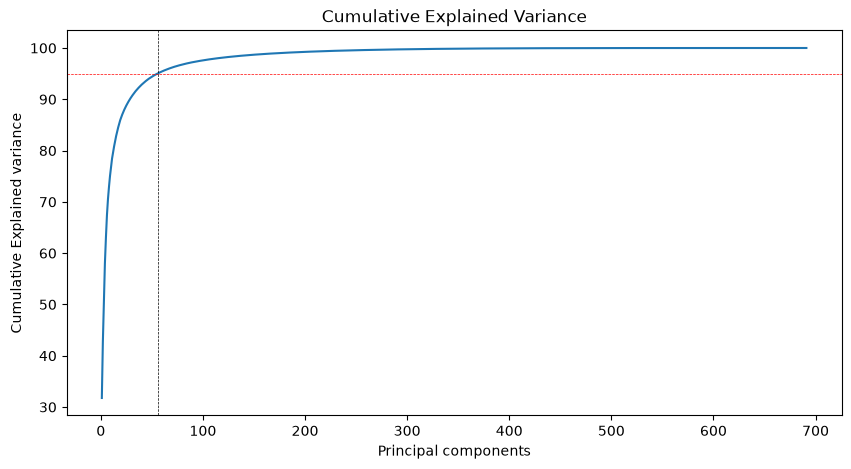

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var)
plt.axhline(95, color='r', lw=0.5, linestyle='--')
plt.axvline(k, color='k', lw=0.5, linestyle='--')
plt.title("Cumulative Explained Variance")
plt.xlabel("Principal components")
plt.ylabel("Cumulative Explained variance")
plt.show()

(691, 56)
(691, 1095)


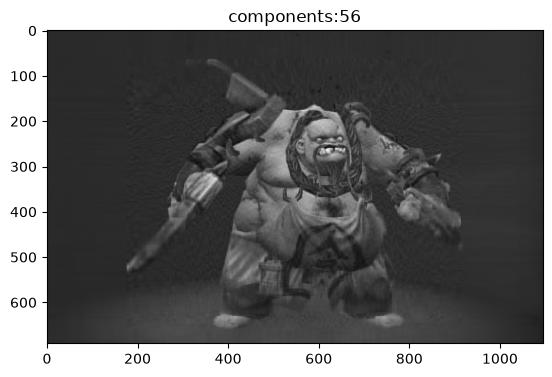

In [9]:
pca_k = PCA(n_components=k)
compressed = pca_k.fit_transform(image_bw)
reconstructed = pca_k.inverse_transform(compressed)

print(compressed.shape)
print(reconstructed.shape)
plt.imshow(reconstructed, cmap='gray')

plt.title(f"components:{k}")

plt.show()

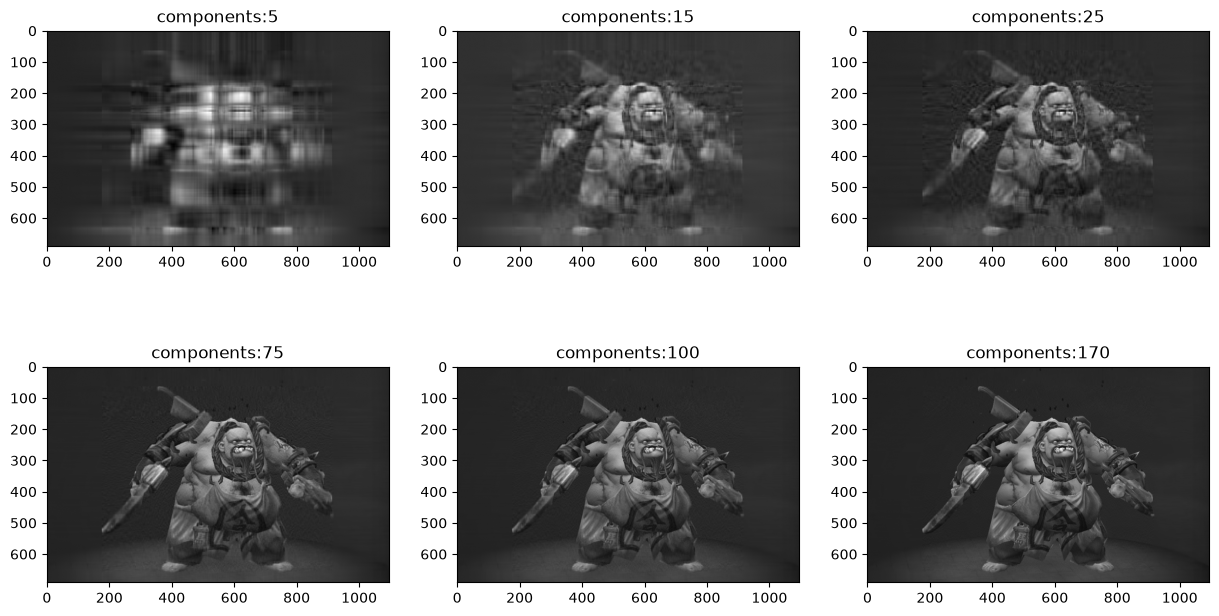

In [10]:
ks = [5, 15, 25, 75, 100, 170]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, n in zip(axes.flat, ks):
    pca_n = PCA(n_components=n)
    compressed = pca_n.fit_transform(image_bw)
    reconstructed = pca_n.inverse_transform(compressed)
    ax.imshow(reconstructed, cmap='gray')
    ax.set_title(f"components:{n}")
plt.show()

5 компонентів помітні світлі й темні плями. При 15–25 компонентах з’являється силует, проте зображення містить багато шумів. Починаючи з 75 компонентів, зображення стає близьким до оригіналу. Збільшення кількості компонентів робить зображення чіткішим, але після досягнення ~100 компонентів різниця стає майже непомітною